<h1 ><big><center>Object recognition and computer vision 2026/2027</center></big></h1>

<h3><big><center><a href="http://imagine.enpc.fr/~varolg/">Gül Varol</a>, <a href="https://www.di.ens.fr/~ponce/">Jean Ponce</a>, <a href="https://www.di.ens.fr/willow/people_webpages/cordelia/">Cordelia Schmid</a>, <a href="https://www.di.ens.fr/~laptev/">Ivan Laptev</a>, <a href="http://people.ciirc.cvut.cz/~sivic/">Josef Sivic</a> and <a href="https://vincentlepetit.github.io/">Vincent Lepetit</a></center></big></h3>


<h2><big><center> Assignment 2: Neural networks</center></big></h2>

<h5><big><center>Adapted from practicals from <a href="http://nicolas.le-roux.name/">Nicolas le Roux</a>, 
  <br><a href="http://www.robots.ox.ac.uk/~vgg/practicals/overview/index.html">Andrea Vedaldi and Andrew Zisserman</a> and <a href="https://cs.nyu.edu/~fergus/teaching/vision/">Rob Fergus</a>
  <br> by <a href="https://www.di.ens.fr/~varol/">Gul Varol</a> and <a href="https://www.di.ens.fr/~iroccosp/">Ignacio Rocco</a></center></big></h5>


</br>

<p align="center">
<img height=300px src="http://www.di.ens.fr/willow/teaching/recvis_orig/assignment3/images/fullyconn.png"/></p>
<p align="center">Figure 1</p>
<p align="center"></p>

**STUDENT**:  YOUR NAME HERE

**EMAIL**:  YOUR EMAIL HERE

# Guidelines

The purpose of this assignment is that you get hands-on experience with the topics covered in class, which will help you understand these topics better. Therefore, **it is imperative that you do this assignment yourself. No code sharing will be tolerated.**

Once you have completed the assignment, you will submit the `ipynb` file containing **both** code and results. For this, make sure to **run your notebook completely before submitting**.

The `ipynb` must be named using the following format: **A2_LASTNAME_Firstname.ipynb**, and submitted in the **Google Classroom page**, together with the video of Task 1.1, named **A2_LASTNAME_Firstname_task1.1.mp4** (or another common video format).

# Required response tracker

| Task | Required deliverable |
|---|---|
| 1.1 | Written derivation of the gradient of the logistic loss w.r.t. `Wi`, `bi`, `Wo`, `bo`, and a video (< 5 min) of you deriving it by hand |
| 1.2 | `gradient_nn(...)` implementation |
| 1.3 | Written general formula for numerical differentiation |
| 1.4 | Gradient check passing (`gradcheck` prints `SUCCESS`) |
| 1.5 | Code printing the final training/validation error table for 5 random initializations, and written answer on differences |
| 1.6 | Written discussion of the training behaviour for different learning rates |
| 1.7 | Code, decision boundaries, final-error and evolution figures, and written discussion for different numbers of hidden units |
| 2.1 | Written response on the hand-designed filter, RGB channel handling, and detected structures |
| 2.2 | Written interpretation of the max-pooling result |
| 3.1 | Code and figure displaying 5 labeled CIFAR-10 images |
| 3.2 | `ConvNet` implementation |
| 3.3 | Written explanation of why CNNs need non-linearities |
| 3.4 | Code and figure of the first convolutional layer weights (after the 20-epoch training) |
| 3.5 | Written answer on the feature-map size after each layer, weight dimensionality and total parameter count |

Use this table as a checklist while progressing through the notebook. The unnumbered `:: SAMPLE TASK ::` (learning-rate experiment) is provided in the notebook and is not a required deliverable; Task 1.6 asks for its written discussion. Note that training the CNN for 20 epochs is part of the unnumbered run, not a deliverable of its own.

# Goal


The goal of this assignment is to get basic knowledge and hands-on experience with training and using neural networks. In Part 1 of the assignment you will implement and experiment with the training and testing of a simple two layer fully-connected neural network, similar to the one depicted in Figure 1 above. In Part 2 you will learn about convolutional neural networks, their motivation, building blocks, and how they are trained. Finally, in part 3 you will train a CNN for classification using the CIFAR-10 dataset.

# Part 1 - Training a fully connected neural network

## Getting started

You will be working with a two layer neural network of the following form 

\begin{equation}
H=\text{ReLU}(W_i X+B_i)\\
Y=W_oH+B_o
\tag{1}
\end{equation}

where $X$ is the input, $Y$ is the output, $H$ is the hidden layer, and $W_i$, $W_o$, $B_i$ and $B_o$ are the network parameters that need to be trained. Here the subscripts $i$ and $o$ stand for the *input* and *output* layer, respectively. This network was also discussed in the class and is illustrated in the above figure where the input units are shown in green, the hidden units in blue and the output in yellow. This network is implemented in the function `nnet_forward_logloss`.

You will train the parameters of the network from labelled training data $\{X^n,Y^n\}$ where $X^n$ are points in $\mathbb{R}^2$ and $Y^n\in\{-1,1\}$ are labels for each point. You will use the stochastic gradient descent algorithm discussed in the class to minimize the loss of the network on the training data given by 

\begin{equation}
L=\sum_n s(Y^n,\bar{Y}(X^n))
\tag{2}
\end{equation}

where $Y^n$ is the target label for the n-th example and $\bar{Y}(X^n)$ is the network’s output for the n-th example $X^n$. The skeleton of the training procedure is provided in the `train_loop` function. 

We will use the logistic loss, which has the following form:

\begin{equation}
s(Y, \bar{Y}(X))=\log(1+\exp(-Y. \bar{Y}(X))
\tag{3}
\end{equation}

where $Y$ is the target label and $\bar{Y}(X)$ is the output of the network for input example $X$. With the logistic loss, the output of the network can be interpreted as a probability $P(\text{class}=1|X) =\sigma(X)$ , where $\sigma(X) =1/(1+\exp(-X))$ is the sigmoid function. Note also that $P(\text{class}=-1|X)=1-P(\text{class}=1|X)$.

In [2]:
# Install the packages needed for this assignment.
# On Google Colab they are all preinstalled, so this is a quick no-op (no restart needed).
%pip install -q numpy scipy matplotlib pillow torch torchvision

In [6]:
from IPython import display
import matplotlib.pyplot as plt
import numpy as np
import scipy.io as sio


def decision_boundary_nnet(X, Y, Wi, bi, Wo, bo):
    x_min, x_max = -2, 4
    y_min, y_max = -5, 3
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), np.arange(y_min, y_max, 0.05))

    XX = np.vstack((xx.ravel(), yy.ravel())).T
    input_hidden = np.dot(XX, Wi) + bi
    hidden = np.maximum(input_hidden, 0)
    Z = np.dot(hidden, Wo) + bo

    # Put the result into a color plot
    Z = Z.reshape(xx.shape)
    plt.contourf(xx, yy, Z > 0, cmap=plt.cm.Paired)
    plt.axis("off")

    # Plot also the training points
    plt.scatter(X[:, 0], X[:, 1], c=Y, cmap="winter")
    plt.axis([-2, 4, -5, 3])
    plt.draw()


def sigm(x):
    # Returns the sigmoid of x.
    return np.exp(-np.logaddexp(0, -x))  # = 1 / (1 + exp(-x)), computed without overflow


def nnet_forward_logloss(X, Y, Wi, bi, Wo, bo):
    """
    Compute the output Po, Yo and the loss of the network for the input X
    This is a 2 layer (1 hidden layer network)

    Input:
        X ... (in R^2) set of input points, one per row
        Y ... {-1,1} the target values for the set of points X
        Wi, bi, Wo, bo ... parameters of the network

    Output:
       Po ... probabilisitc output of the network P(class=1 | x)
                  Po is in <0 1>.
                  Note: P(class=-1 | x ) = 1 - Po
       Yo ... output of the network Yo is in <-inf +inf>
       loss ... logistic loss of the network on examples X with ground target
                    values Y in {-1,1}
    """
    # Hidden layer
    hidden = np.maximum(np.dot(X, Wi) + bi, 0)
    # Output of the network
    Yo = np.dot(hidden, Wo) + bo
    # Probabilistic output
    Po = sigm(Yo)
    # Logistic loss
    loss = np.logaddexp(0, -Y * Yo)  # = log(1 + exp(-Y * Yo)), computed without overflow
    return Po, Yo, loss


# Load the training data
!wget -nc -q http://www.di.ens.fr/willow/teaching/recvis_orig/assignment2/double_moon_train1000.mat
train_data = sio.loadmat("./double_moon_train1000.mat", squeeze_me=True)
Xtr = train_data["X"]
Ytr = train_data["Y"]
# Load the validation data
!wget -nc -q http://www.di.ens.fr/willow/teaching/recvis_orig/assignment2/double_moon_val1000.mat
val_data = sio.loadmat("./double_moon_val1000.mat", squeeze_me=True)
Xval = val_data["X"]
Yval = val_data["Y"]

## Computing gradients of the loss with respect to network parameters 

### :: TASK 1.1 ::
Derive the form of the gradient of the logistic loss (3) with respect to the parameters of the network $W_i$, $W_o$, $B_i$ and $B_o$.  *Hint:* Use the chain rule as discussed in the class.

**Video.** In addition to the written answer below, record a short video (**between 1 and 5 minutes**) of yourself deriving these gradients **by hand** (on paper, a tablet, a whiteboard, …) while explaining each step out loud. A phone or laptop camera pointed at your paper is enough. We expect to see you and hear **your voice** in this video with a natural narration (**do not use generative AI in the production**). The goal is to check you understood the derivation, no need for a professional recording. We will not distribute these videos and only the class instructor Gül Varol and the TAs (Alexandros Benetatos and Fernando Cendra) will view them. We will delete the videos by the end of the MVA academic year. Submit it on Google Classroom together with the notebook, named **A2_LASTNAME_Firstname_task1.1.mp4**.

<div style="border: 3px dashed #d97706; border-radius: 10px; padding: 14px; margin: 10px 0;">
<strong>✍️ REQUIRED WRITTEN RESPONSE — TASK 1.1</strong><br>

Provide the derivations for $\frac{\partial s}{\partial W_i}$, $\frac{\partial s}{\partial W_o}$, $\frac{\partial s}{\partial B_i}$, $\frac{\partial s}{\partial B_o}$, and submit the video described above (< 5 min, `A2_LASTNAME_Firstname_task1.1.mp4`).

<strong>Replace the placeholder below with your response. Do not delete this heading.</strong>
</div>

#### Your response

We have those equations for the neural network:

$$
Z = W_i^{\top} X + B_i\qquad
H = \mathrm{ReLU}(Z) = \max(Z,0)\qquad
\bar{Y} = W_o^{\top} H + B_o\qquad
s(Y,\bar{Y}) = \log\bigl(1 + \exp(-Y\,\bar{Y})\bigr)
$$

**Gradient of the loss with respect to the network output** (we will reuse it below):

$$
\frac{\partial s}{\partial \bar{Y}}= \frac{-Y\,\exp(-Y\bar{Y})}{1+\exp(-Y\bar{Y})}= -\frac{Y}{1+\exp(Y\bar{Y})}
$$

We denote $\delta_{out} = \dfrac{\partial s}{\partial \bar{Y}}$


**Gradient of the loss with respect to the output-layer parameters ($W_o$, $B_o$)**

The loss $s$ depends on $W_o$ and $B_o$ only through $\bar{Y}$. Using the chain rule:

$$
\frac{\partial s}{\partial B_o}= \frac{\partial s}{\partial \bar{Y}}\,\frac{\partial \bar{Y}}{\partial B_o}
\qquad
\frac{\partial s}{\partial W_o}= \frac{\partial s}{\partial \bar{Y}}\,\frac{\partial \bar{Y}}{\partial W_o}
$$

- $\dfrac{\partial s}{\partial \bar{Y}} = \delta_{out}$
- since $\bar{Y} = W_o^{\top} H + B_o$, we have $\dfrac{\partial \bar{Y}}{\partial B_o} = 1$
- and $\dfrac{\partial \bar{Y}}{\partial W_o} = H^T$

Therefore:

$$
\frac{\partial s}{\partial B_o} = \delta_{out}\cdot 1 = \delta_{out}
\qquad
\frac{\partial s}{\partial W_o} = \delta_{out} H^T
$$


**Gradient of the loss with respect to the hidden layer**

Again by the chain rule, $s$ depends on $H$ only through $\bar{Y}$:

$$
\frac{\partial s}{\partial H}= \frac{\partial s}{\partial \bar{Y}}\ \frac{\partial \bar{Y}}{\partial H}
$$

- $\dfrac{\partial s}{\partial \bar{Y}} = \delta_{out}$
- since $\bar{Y} = W_o^{\top} H + B_o$, we have $\dfrac{\partial \bar{Y}}{\partial H} = W_o^T$

Hence:

$$
\frac{\partial s}{\partial H} = \delta_{out} W_o^T
$$

Then $H = \mathrm{ReLU}(Z)$, so by the chain rule:

$$
\frac{\partial s}{\partial Z}= \frac{\partial s}{\partial H} \frac{\partial H}{\partial Z}
$$

- $\dfrac{\partial s}{\partial H} = \delta_{out} W_o^T$
- $\dfrac{\partial H}{\partial Z} = \mathrm{ReLU}'(Z) = \mathbf{1}_{Z>0}$

Then :
$$
\frac{\partial s}{\partial Z} = \delta_{out} W_o^T \cdot \mathbf{1}_{Z>0}
$$


**Gradient of the loss with respect to the input-layer parameters ($W_i$, $B_i$)**

The loss $s$ depends on $W_i$ and $B_i$ only through $Z$. Using the chain rule:

$$
\frac{\partial s}{\partial B_i}= \frac{\partial s}{\partial Z}\,\frac{\partial Z}{\partial B_i}
\qquad
\frac{\partial s}{\partial W_i}= \frac{\partial s}{\partial Z}\,\frac{\partial Z}{\partial W_i}
$$

- $\dfrac{\partial s}{\partial Z} = \delta_{out}\, W_o \cdot \mathbf{1}_{Z>0}$
- since $Z = W_i^{\top} X + B_i$, we have $\dfrac{\partial Z}{\partial B_i} = 1$
- and $\dfrac{\partial Z}{\partial W_i} = X^T$

Therefore:

$$
\frac{\partial s}{\partial B_i} = \delta_{out}\, W_o \cdot \mathbf{1}_{Z>0}
\qquad
\frac{\partial s}{\partial W_i} = \bigl(\delta_{out}\, W_o \cdot \mathbf{1}_{Z>0}\bigr)X^T
$$


In the end (after replacing $\delta_{out}$):

$$
\boxed{
\begin{aligned}
\frac{\partial s}{\partial B_o} &= -\frac{Y}{1+\exp(Y\bar{Y})}\\
\frac{\partial s}{\partial W_o} &= -\frac{Y}{1+\exp(Y\bar{Y})}\, H^T\\
\frac{\partial s}{\partial B_i} &= -\frac{Y}{1+\exp(Y\bar{Y})}\, W_o \cdot \mathbf{1}_{Z>0}\\
\frac{\partial s}{\partial W_i} &= \left(-\frac{Y}{1+\exp(Y\bar{Y})}\, W_o \cdot \mathbf{1}_{Z>0}\right)X^T
\end{aligned}
}
$$

### :: TASK 1.2 ::

Following your derivation, implement the gradient computation in the function `gradient_nn`. See the code for the description of the required inputs / outputs of this function.

<div style="border: 3px solid #d97706; border-radius: 10px; padding: 12px; margin: 14px 0;">
<strong>🧩 REQUIRED CODE — TASK 1.2</strong><br>
Complete the function in the code cell immediately below. It must return <code>grad_s_Wi</code>, <code>grad_s_bi</code>, <code>grad_s_Wo</code>, and <code>grad_s_bo</code>.
</div>

In [7]:
# ============================================================
# STUDENT TODO — TASK 1.2 (REQUIRED)
# Complete the indicated section and remove the
# NotImplementedError before continuing.
# ============================================================


def gradient_nn(X, Y, Wi, bi, Wo, bo):
    """
    Compute gradient of the logistic loss of the neural network on example X with
    target label Y, with respect to the parameters Wi,bi,Wo,bo.

    Input:
        X ... 2d vector of the input example
        Y ... the target label in {-1,1}
        Wi,bi,Wo,bo ... parameters of the network
        Wi ... [dxh]
        bi ... [h]
        Wo ... [h]
        bo ... 1
        where h... is the number of hidden units
              d... is the number of input dimensions (d=2)

    Output:
        grad_s_Wi [dxh] ... gradient of loss s(Y,Y(X)) w.r.t  Wi
        grad_s_bi [h]   ... gradient of loss s(Y,Y(X)) w.r.t. bi
        grad_s_Wo [h]   ... gradient of loss s(Y,Y(X)) w.r.t. Wo
        grad_s_bo 1     ... gradient of loss s(Y,Y(X)) w.r.t. bo
    """

    ##########################
    #                        #
    #  WRITE YOUR CODE HERE  #
    #                        #
    ##########################
    
    
    Z = np.dot(X, Wi) + bi
    H = np.maximum(Z, 0)
    Ybar = np.dot(H, Wo) + bo

    delta_out = -Y / (1 + np.exp(Y * Ybar))

    grad_s_bo = delta_out
    grad_s_Wo = delta_out * H
    grad_s_bi = delta_out * Wo * (Z > 0)
    grad_s_Wi = np.outer(X, grad_s_bi)
    
    return grad_s_Wi, grad_s_bi, grad_s_Wo, grad_s_bo

## Numerically verify the gradients
Here you will numerically verify that your analytically computed gradients in function `gradient_nn` are correct. 

### :: TASK 1.3 ::
Write down the general formula for numerically computing the approximate derivative of the loss $s(\theta)$, with respect to the parameter $\theta_i$ using finite differencing.  *Hint: use the first order Taylor expansion of loss $s(\theta+\Delta \theta)$ around point $\theta$.*

<div style="border: 3px dashed #d97706; border-radius: 10px; padding: 12px; margin: 14px 0;">
<strong>✍️ REQUIRED WRITTEN RESPONSE — TASK 1.3</strong><br>
Provide the derivation for $s'(\theta)$.
<strong>Replace the placeholder below with your response. Do not delete this heading.</strong>
</div>

#### Your response

In general, using the Taylor expansion, one have : 
$$
s(\theta + \Delta\theta)\approx s(\theta) + s'(\theta)\Delta\theta
$$
So :
$$
s'(\theta)\approx \frac{s(\theta + \Delta\theta) - s(\theta)}{\Delta\theta}
$$

Defining the unit vector $\epsilon_i$ in the direction of $\theta_i$, one can then write : 
$$
\frac{\partial s}{\partial \theta_i} \approx \frac{s(\theta + \epsilon e_i) - s(\theta)}{\epsilon}
$$
with $\epsilon$ a scalar with a small norm.

Following the general formula, `gradient_nn_numerical` function numerically computes the derivatives of the loss function with respect to all the parameters of the network $W_i$, $W_o$, $B_i$ and $B_o$:

In [8]:
def gradient_nn_numerical(X, Y, Wi, bi, Wo, bo):
    """
    Compute numerical gradient of the logistic loss of the neural network on
    example X with target label Y, with respect to the parameters Wi,bi,Wo,bo.

    Input:
       X ... 2d vector of the input example
       Y ... the target label in {-1,1}
       Wi, bi, Wo, bo ... parameters of the network
       Wi ... [dxh]
       bi ... [h]
       Wo ... [h]
       bo ... 1
       where h... is the number of hidden units
             d... is the number of input dimensions (d=2)

    Output:
       grad_s_Wi_numerical [dxh] ... gradient of loss s(Y,Y(X)) w.r.t  Wi
       grad_s_bi_numerical [h]   ... gradient of loss s(Y,Y(X)) w.r.t. bi
       grad_s_Wo_numerical [h]   ... gradient of loss s(Y,Y(X)) w.r.t. Wo
       grad_s_bo_numerical 1     ... gradient of loss s(Y,Y(X)) w.r.t. bo
    """

    eps = 1e-8
    grad_s_Wi_numerical = np.zeros(Wi.shape)
    grad_s_bi_numerical = np.zeros(bi.shape)
    grad_s_Wo_numerical = np.zeros(Wo.shape)

    for i in range(Wi.shape[0]):
        for j in range(Wi.shape[1]):
            dummy, dummy, pos_loss = nnet_forward_logloss(X, Y, sumelement_matrix(Wi, i, j, +eps), bi, Wo, bo)
            dummy, dummy, neg_loss = nnet_forward_logloss(X, Y, sumelement_matrix(Wi, i, j, -eps), bi, Wo, bo)
            grad_s_Wi_numerical[i, j] = (pos_loss - neg_loss) / (2 * eps)

    for i in range(bi.shape[0]):
        dummy, dummy, pos_loss = nnet_forward_logloss(X, Y, Wi, sumelement_vector(bi, i, +eps), Wo, bo)
        dummy, dummy, neg_loss = nnet_forward_logloss(X, Y, Wi, sumelement_vector(bi, i, -eps), Wo, bo)
        grad_s_bi_numerical[i] = (pos_loss - neg_loss) / (2 * eps)

    for i in range(Wo.shape[0]):
        dummy, dummy, pos_loss = nnet_forward_logloss(X, Y, Wi, bi, sumelement_vector(Wo, i, +eps), bo)
        dummy, dummy, neg_loss = nnet_forward_logloss(X, Y, Wi, bi, sumelement_vector(Wo, i, -eps), bo)
        grad_s_Wo_numerical[i] = (pos_loss - neg_loss) / (2 * eps)

    dummy, dummy, pos_loss = nnet_forward_logloss(X, Y, Wi, bi, Wo, bo + eps)
    dummy, dummy, neg_loss = nnet_forward_logloss(X, Y, Wi, bi, Wo, bo - eps)
    grad_s_bo_numerical = (pos_loss - neg_loss) / (2 * eps)

    return grad_s_Wi_numerical, grad_s_bi_numerical, grad_s_Wo_numerical, grad_s_bo_numerical


def sumelement_matrix(X, i, j, element):
    Y = np.copy(X)
    Y[i, j] = X[i, j] + element
    return Y


def sumelement_vector(X, i, element):
    Y = np.copy(X)
    Y[i] = X[i] + element
    return Y

### :: TASK 1.4 ::

Run the following code snippet and understand what it is doing. `gradcheck` function checks that the analytically computed derivative using function `gradient_nn` (e.g. `grad_s_bo`) at the same training example $\{X,Y\}$ is the same (up to small errors) as your numerically computed value of the derivative using function `gradient_nn_numerical` (e.g. `grad_s_bo_numerical`). Make sure the output is `SUCCESS` to move on to the next task.

In [9]:
def gradcheck():
    """
    Check that the numerical and analytical gradients are the same up to eps
    """
    h = 3  # number of hidden units
    eps = 1e-6
    for i in range(1000):
        # Generate random input/output/weight/bias
        X = np.random.randn(2)
        Y = 2 * np.random.randint(2) - 1  # {-1, 1}
        Wi = np.random.randn(X.shape[0], h)
        bi = np.random.randn(h)
        Wo = np.random.randn(h)
        bo = np.random.randn()
        # Compute analytical gradients
        grad_s_Wi, grad_s_bi, grad_s_Wo, grad_s_bo = gradient_nn(X, Y, Wi, bi, Wo, bo)
        # Compute numerical gradients
        grad_s_Wi_numerical, grad_s_bi_numerical, grad_s_Wo_numerical, grad_s_bo_numerical = gradient_nn_numerical(
            X, Y, Wi, bi, Wo, bo
        )
        # Compute the difference between analytical and numerical gradients
        delta_Wi = np.mean(np.abs(grad_s_Wi - grad_s_Wi_numerical))
        delta_bi = np.mean(np.abs(grad_s_bi - grad_s_bi_numerical))
        delta_Wo = np.mean(np.abs(grad_s_Wo - grad_s_Wo_numerical))
        delta_bo = np.abs(grad_s_bo - grad_s_bo_numerical)
        # Difference larger than a threshold
        if delta_Wi > eps or delta_bi > eps or delta_Wo > eps or delta_bo > eps:
            return False

    return True


# Check gradients
if gradcheck():
    print("SUCCESS: Passed gradcheck.")
else:
    print("FAILURE: Fix your gradient_nn implementation.")

SUCCESS: Passed gradcheck.


## Training the network using backpropagation and experimenting with different parameters

Use the provided code below that calls the `train_loop` function. Set the number of hidden units to 7 by setting $h=7$ in the code and set the learning rate to 0.02 by setting `lrate = 0.02`. Run the training code. Visualize the trained hyperplane using the provided function `decision_boundary_nnet(Xtr, Ytr, Wi, bi, Wo, bo)`. Show also the evolution of the training and validation errors. Include the decision hyper-plane visualization and the training and validation error plots.

In [12]:
def train_loop(Xtr, Ytr, Xval, Yval, h, lrate, vis="all", nEpochs=100):
    """
    Train the network with SGD and record the training / validation errors after every iteration

    Input:
        Xtr ... Nx2 matrix of training samples
        Ytr ... N dimensional vector of training labels
        Xval ... Nx2 matrix of validation samples
        Yval ... N dimensional vector validation labels
        h ... number of hidden units
        lrate ... learning rate
        vis ... visulaization option ('all' | 'last' | 'never')
        nEpochs ... number of training epochs

    Output:
        tr_error ... nEpochs*nSamples dimensional vector of training error
        val_error ... nEpochs*nSamples dimensional vector of validation error
    """

    nSamples = Xtr.shape[0]
    tr_error = np.zeros(nEpochs * nSamples)
    val_error = np.zeros(nEpochs * nSamples)

    # Randomly initialize parameters of the model
    Wi = np.random.randn(Xtr.shape[1], h)
    Wo = np.zeros(h)
    bi = np.zeros(h)
    bo = 0.0

    if vis == "all" or vis == "last":
        plt.figure()

    for i in range(nEpochs * nSamples):
        # Draw an example at random
        n = np.random.randint(nSamples)
        X = Xtr[n]
        Y = Ytr[n]

        # Compute gradient
        grad_s_Wi, grad_s_bi, grad_s_Wo, grad_s_bo = gradient_nn(X, Y, Wi, bi, Wo, bo)

        # Gradient update
        Wi -= lrate * grad_s_Wi
        Wo -= lrate * grad_s_Wo
        bi -= lrate * grad_s_bi
        bo -= lrate * grad_s_bo

        # Compute training error
        Po, Yo, loss = nnet_forward_logloss(Xtr, Ytr, Wi, bi, Wo, bo)
        Yo_class = np.sign(Yo)
        tr_error[i] = 100 * np.mean(Yo_class != Ytr)

        # Compute validation error
        Pov, Yov, lossv = nnet_forward_logloss(Xval, Yval, Wi, bi, Wo, bo)
        Yov_class = np.sign(Yov)
        val_error[i] = 100 * np.mean(Yov_class != Yval)

        # Plot (at every epoch if visualization is 'all', only at the end if 'last')
        if (vis == "all" and i % nSamples == 0) or (vis == "last" and i == nEpochs * nSamples - 1):
            # Draw the decision boundary.
            plt.clf()
            plt.title("p = %d, Iteration = %.d, Error = %.3f" % (h, i / nSamples, tr_error[i]))
            decision_boundary_nnet(Xtr, Ytr, Wi, bi, Wo, bo)
            display.display(plt.gcf(), display_id=True)
            display.clear_output(wait=True)

    if vis == "all":
        # Plot the evolution of the training and test errors
        plt.figure()
        plt.plot(tr_error, label="training")
        plt.plot(val_error, label="validation")
        plt.legend()
        plt.title("Training/validation errors: %.2f%% / %.2f%%" % (tr_error[-1], val_error[-1]))
    return tr_error, val_error

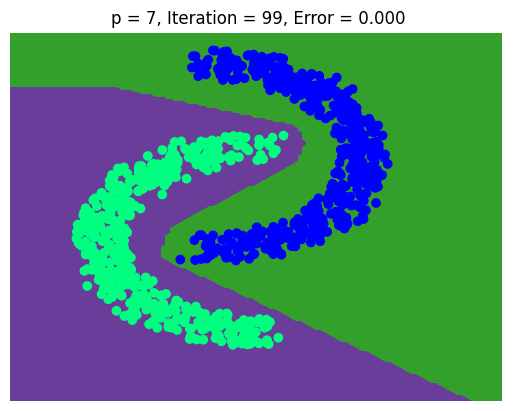

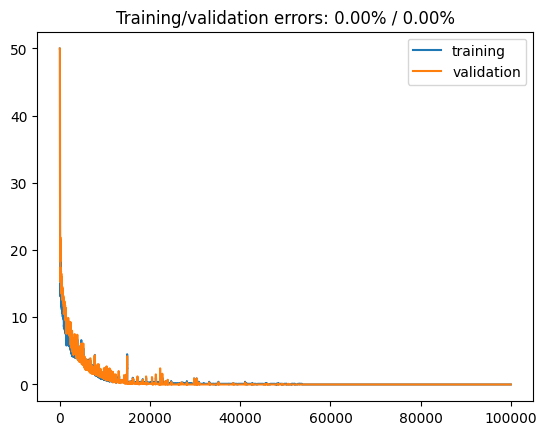

In [9]:
# Run training
h = 7
lrate = 0.02
tr_error, val_error = train_loop(Xtr, Ytr, Xval, Yval, h, lrate)

### :: TASK 1.5 ::

**Random initializations.** Repeat this procedure 5 times from 5 different random initializations, training each time for **10 epochs** (`nEpochs=10`). Record for each run the final training and validation errors. Did the network always converge to zero training error? Do the 5 runs end with the same errors? Summarize your final training and validation errors into a table for the 5 runs. You do not need to include the decision hyper-plane visualizations. Note: to speed-up the training you can plot the visualization figures less often (or never) and hence speed-up the training.

<div style="border: 3px solid #d97706; border-radius: 10px; padding: 12px; margin: 14px 0;">
<strong>🧩 REQUIRED CODE — TASK 1.5</strong><br>
Complete the code cell immediately below. It must print a table of train and validation errors for each of the 5 trials. Then answer the question in the cell after it.
</div>

In [18]:
# ============================================================
# STUDENT TODO — TASK 1.5 (REQUIRED)
# Expected outputs: table of the final errors of the 5 runs (10 epochs each)
# Complete the indicated section and remove the
# NotImplementedError before continuing.
# ============================================================

# TODO:
for i in range (5):
    tr_error, val_error = train_loop(Xtr, Ytr, Xval, Yval, h, lrate,nEpochs=10,vis=None)
    print(f"{'Run':>4} | {'Train error':10} | {'Val error':5}")
    print(f"{i+1:>4} | {tr_error[-1]:10.2f} | {val_error[-1]:5.2f}")


    


 Run | Train error | Val error
   1 |       0.50 |  0.50
 Run | Train error | Val error
   2 |       1.60 |  2.10
 Run | Train error | Val error
   3 |       0.40 |  0.30
 Run | Train error | Val error
   4 |       0.50 |  0.50
 Run | Train error | Val error
   5 |       0.80 |  0.80


<div style="border: 3px dashed #d97706; border-radius: 10px; padding: 12px; margin: 14px 0;">
<strong>✍️ REQUIRED WRITTEN RESPONSE — TASK 1.5</strong><br>
Based on your table, answer in 2-3 sentences: Did the network always converge to zero training error? Do the 5 runs end with the same errors, and why? Why do the following tasks average their results over 5 runs?
<strong>Replace the placeholder below with your response. Do not delete this heading.</strong>
</div>

#### Your response

The network did not converge to zero training error in any of the 5 runs but it is still sometimes very close to 0 (0,40 % for example). However, some runs get a much higher train/val errors (run 2), this can be explain because each run starts from a different random initialization, so SGD follows a different path and fall in a different local minima. Averaging over 5 runs in later tasks reduces the varability of results by avoiding the dependance in the intialization. This gives a more reliable estimation of performance.

### :: SAMPLE TASK ::

For this task, the answer is given. Run the given code and answer Task 1.7 similarly.

**Learning rate:**

Keep $h=7$ and change the learning rate to values $\text{lrate} = \{2, 0.2, 0.02, 0.002\}$. For each of these values run the training procedure 5 times and observe the training behaviour. You do not need to include the decision hyper-plane visualizations in your answer.

**- Make one figure** where *final* error for (i) training and (ii) validation sets are superimposed. $x$-axis should be the different values of the learning rate, $y$-axis the error *mean* across 5 runs. Show the standard deviation with error bars and make sure to label each plot with a legend.

**- Make another figure** where *training error evolution* for each learning rate is superimposed. $x$-axis should be the iteration number, $y$-axis the training error *mean* across 5 runs for a given learning rate. Show the standard deviation with error bars and make sure to label each curve with a legend.

In [ ]:
nEpochs = 40
trials = 5
lrates = [2, 0.2, 0.02, 0.002]
plot_data_h = np.zeros((2, trials, len(lrates), nEpochs * 1000))
h = 7
for j, lrate in enumerate(lrates):
    print("LR = %f" % lrate)
    for i in range(trials):
        tr_error, val_error = train_loop(Xtr, Ytr, Xval, Yval, h, lrate, vis="never", nEpochs=nEpochs)
        plot_data_h[0, i, j, :] = tr_error
        plot_data_h[1, i, j, :] = val_error

LR = 2.000000


/tmp/ipykernel_3828/816732827.py:42: RuntimeWarning: overflow encountered in exp
  delta_out = -Y / (1 + np.exp(Y * Ybar))


LR = 0.200000
LR = 0.020000
LR = 0.002000


Text(0, 0.5, 'training error')

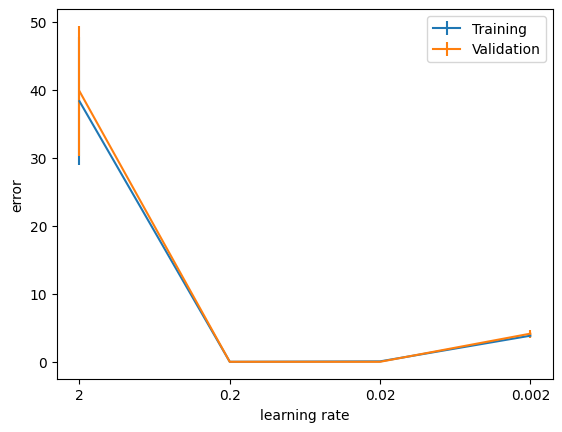

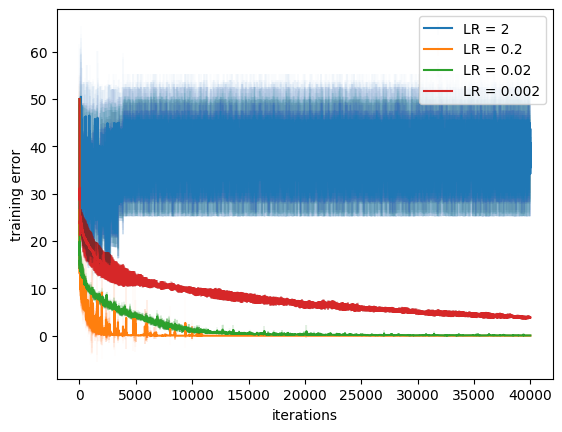

In [ ]:
plt.errorbar(
    np.arange(len(lrates)),
    plot_data_h[0, :, :, -1].mean(axis=0),
    yerr=plot_data_h[0, :, :, -1].std(axis=0),
    label="Training",
)
plt.errorbar(
    np.arange(len(lrates)),
    plot_data_h[1, :, :, -1].mean(axis=0),
    yerr=plot_data_h[1, :, :, -1].std(axis=0),
    label="Validation",
)
plt.xticks(np.arange(len(lrates)), lrates)
plt.xlabel("learning rate")
plt.ylabel("error")
plt.legend()

# Plot the evolution of the training loss for each learning rate
plt.figure()
for j, lrate in enumerate(lrates):
    x = np.arange(plot_data_h.shape[3])
    # Mean training loss over trials
    y = plot_data_h[0, :, j, :].mean(axis=0)
    # Standard deviation over trials
    ebar = plot_data_h[0, :, j, :].std(axis=0)
    # Plot
    markers, caps, bars = plt.errorbar(x, y, yerr=ebar, label="LR = " + str(lrate))
    # Make the error bars transparent
    [bar.set_alpha(0.01) for bar in bars]
plt.legend()
plt.xlabel("iterations")
plt.ylabel("training error")

### :: TASK 1.6 ::

**- Briefly discuss** the different behaviour of the training for different learning rates. How many iterations does it take to converge or does it converge at all? Which learning rate is  better and why?

<div style="border: 3px dashed #d97706; border-radius: 10px; padding: 12px; margin: 14px 0;">
<strong>✍️ REQUIRED WRITTEN RESPONSE — TASK 1.6</strong><br>
<strong>Replace the placeholder below with your response. Do not delete this heading.</strong>
</div>

#### Your response

With lr=2, the training process is unstable and does not converge at all. 
With lr = 0.002, the error seems to go toward zero but in a very slow manner (at 40000 iterations, it has still not converges).Furthermore, it has a significant sandard deviation.
With lr = 0.2 , the error goes quickly toward 0, and the convergence is stabilized with a low standard deviation. However, the first 10000 iterations are very noisy.
Finally, with lr = 0.02, the error converges to zero more slowly (15000 iterations) than the case with lr = 0.2, but its convergence is much more stable and less noisy.

The last case seems to be the better due to its stabilization and its quick enough convergence

### :: TASK 1.7 ::
**The number of hidden units:**

Set the learning rate to 0.02 and change the number of hidden units $h = \{1, 2, 5, 7, 10, 100\}$. For each of these values run the training procedure 5 times and observe the training behaviour

**- Visualize** one decision hyper-plane per number of hidden units.

**- Make one figure** where *final* error for (i) training and (ii) validation sets are superimposed. $x$-axis should be the different values of the number of hidden units, $y$-axis the error *mean* across 5 runs. Show the standard deviation with error bars and make sure to label each plot with a legend.

**- Make another figure** where *training error evolution* for each number of hidden units is superimposed. $x$-axis should be the iteration number, $y$-axis the training error *mean* across 5 runs for a given number of hidden units. Show the standard deviation with error bars and make sure to label each curve with a legend.

**- Briefly discuss** the different behaviours for the different numbers of hidden units.

<div style="border: 3px solid #d97706; border-radius: 10px; padding: 12px; margin: 14px 0;">
<strong>🧩 REQUIRED CODE + ✍️ WRITTEN RESPONSE — TASK 1.7</strong><br>
Follow the "Sample Task" and complete the code cell below outputing the expected figures. Then discuss the effect of changing hidden units.
</div>

Text(0, 0.5, 'training error')

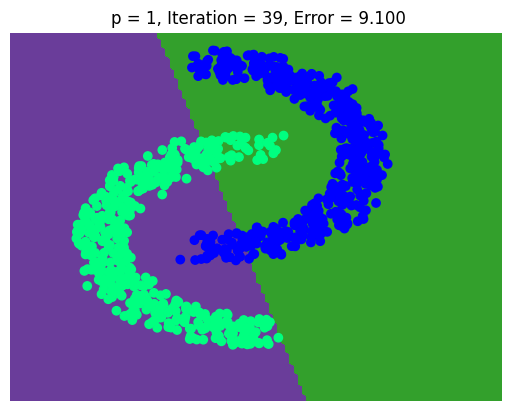

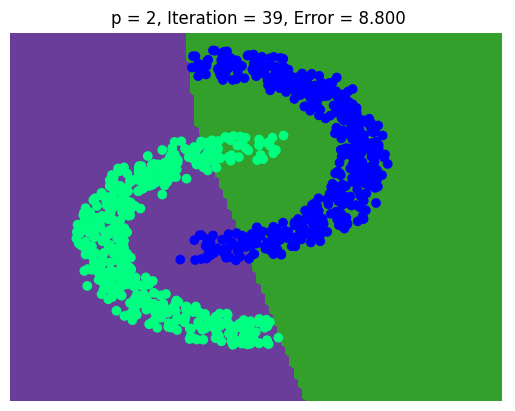

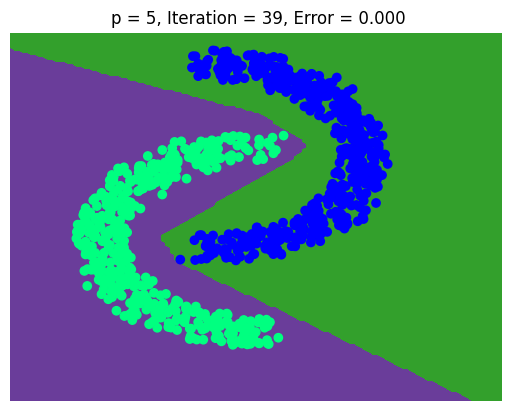

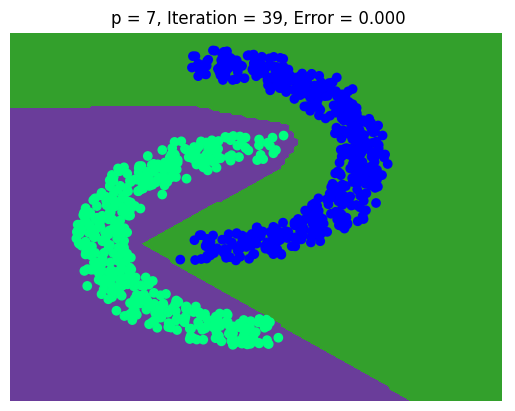

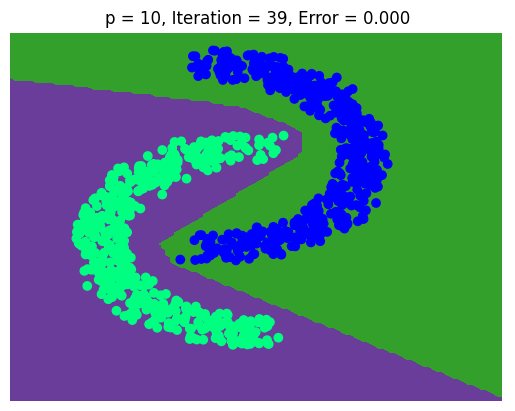

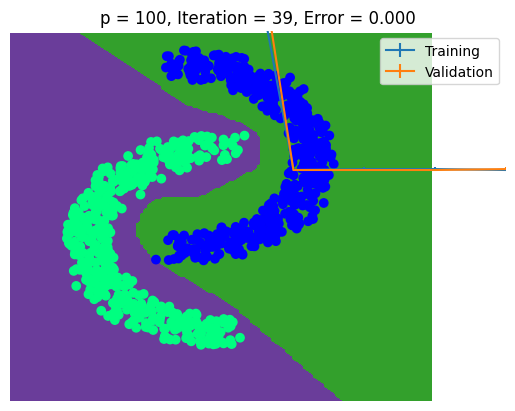

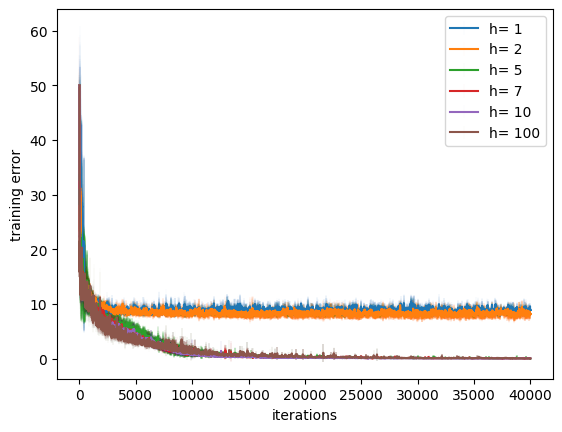

In [ ]:
# ============================================================
# STUDENT TODO — TASK 1.7 (REQUIRED)
# Expected outputs: one decision boundary per h and the two figures described above
# Complete the indicated section and remove the
# NotImplementedError before continuing.
# ============================================================

# TODO:
nEpochs = 40
trials = 5
lrate = 0.02
h = [1,2,5,7,10,100]
plot_data_h = np.zeros((2, trials, len(h), nEpochs * 1000))

for j, h_j in enumerate(h):
    print(f"h =  {h_j}")
    for i in range(trials):
        tr_error, val_error = train_loop(Xtr, Ytr, Xval, Yval, h_j, lrate, vis="last" if i ==0 else "never", nEpochs=nEpochs)
        plot_data_h[0, i, j, :] = tr_error
        plot_data_h[1, i, j, :] = val_error
        


Text(0, 0.5, 'training error')

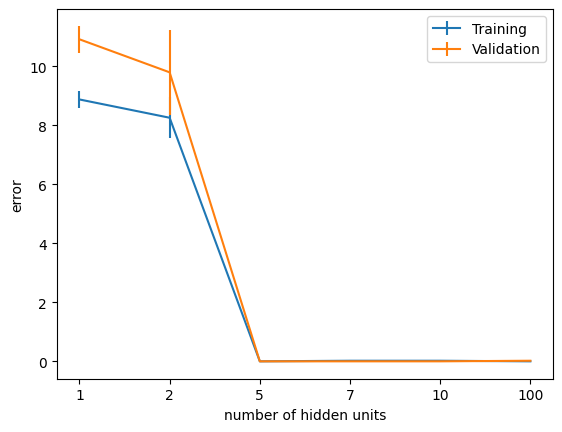

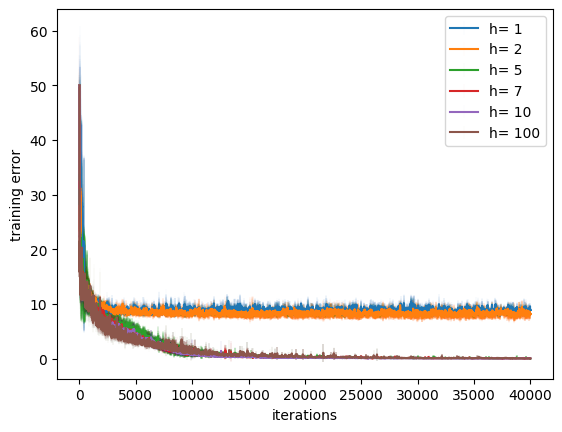

In [14]:
plt.figure()
plt.errorbar(
    np.arange(len(h)),
    plot_data_h[0, :, :, -1].mean(axis=0),
    yerr=plot_data_h[0, :, :, -1].std(axis=0),
    label="Training",
)
plt.errorbar(
    np.arange(len(h)),
    plot_data_h[1, :, :, -1].mean(axis=0),
    yerr=plot_data_h[1, :, :, -1].std(axis=0),
    label="Validation",
)
plt.xticks(np.arange(len(h)), h)
plt.xlabel("number of hidden units")
plt.ylabel("error")
plt.legend()

# Plot the evolution of the training loss for each learning rate
plt.figure()
for j, h_j in enumerate(h):
    x = np.arange(plot_data_h.shape[3])
    # Mean training loss over trials
    y = plot_data_h[0, :, j, :].mean(axis=0)
    # Standard deviation over trials
    ebar = plot_data_h[0, :, j, :].std(axis=0)
    # Plot
    markers, caps, bars = plt.errorbar(x, y, yerr=ebar, label="h= " + str(h_j))
    # Make the error bars transparent
    [bar.set_alpha(0.01) for bar in bars]
plt.legend()
plt.xlabel("iterations")
plt.ylabel("training error")

#### Your response

With h= 1 and h=2, the model cannot fit the data and the final error is very high with a significant standard deviation especilly for h=2 because it has more degrees of freedom.

With h= 5 , 7 and 10, the modele reach a quasi-zero loss with a low standard deviation. The final result is a non-linear frontier with a lot of anguilarity (not a smooth frontier).

with h = 100, we also reach a zero loss and one can remark that the model is much more complex thant the other one and this can bee seen by the smooth frontier.

# Part 2 - Building blocks of a CNN

This part introduces typical CNN building blocks, such as ReLU units and linear filters. For a motivation for using CNNs over fully-connected neural networks, see [[Le Cun, et al, 1998]](http://yann.lecun.com/exdb/publis/pdf/lecun-01a.pdf).


## Check PyTorch

In [1]:
import torch

print(torch.__version__)
print(torch.cuda.is_available())

2.11.0+cu130
True


## Convolution

A feed-forward neural network can be thought of as the composition of number of functions 
$$
f(\mathbf{x}) = f_L(\dots f_2(f_1(\mathbf{x};\mathbf{w}_1);\mathbf{w}_2)\dots),\mathbf{w}_{L}).
$$
Each function $f_l$ takes as input a datum $\mathbf{x}_l$ and a parameter vector $\mathbf{w}_l$ and produces as output a datum $\mathbf{x}_{l+1}$. While the type and sequence of functions is usually handcrafted, the parameters $\mathbf{w}=(\mathbf{w}_1,\dots,\mathbf{w}_L)$ are *learned from data* in order to solve a target problem, for example classifying images or sounds.

In a *convolutional neural network* data and functions have additional structure. The data $\mathbf{x}_1,\dots,\mathbf{x}_n$ are images, sounds, or more in general maps from a lattice $^1$ to one or more real numbers. In particular, since the rest of the practical will focus on computer vision applications, data will be 2D arrays of pixels. Formally, each $\mathbf{x}_i$ will be a $M \times N \times K$ real array of $M \times N$ pixels and $K$ channels per pixel. Hence the first two dimensions of the array span space, while the last one spans channels. Note that only the input $\mathbf{x}=\mathbf{x}_1$ of the network is an actual image, while the remaining data are intermediate *feature maps*.

The second property of a CNN is that the functions $f_l$ have a *convolutional structure*. This means that $f_l$ applies to the input map $\mathbf{x}_l$ an operator that is *local and translation invariant*. Examples of convolutional operators are applying a bank of linear filters to $\mathbf{x}_l$. 

In this part we will familiarise ourselves with a number of such convolutional and non-linear operators. The first one is the regular *linear convolution* by a filter bank. We will start by focusing our attention on a single function relation as follows:
$$
 f: \mathbb{R}^{M\times N\times K} \rightarrow \mathbb{R}^{M' \times N' \times K'},
 \qquad \mathbf{x} \mapsto \mathbf{y}.
$$

$^1$ A two-dimensional *lattice* is a discrete grid embedded in $R^2$, similar for example to a checkerboard.

(384, 512, 3)


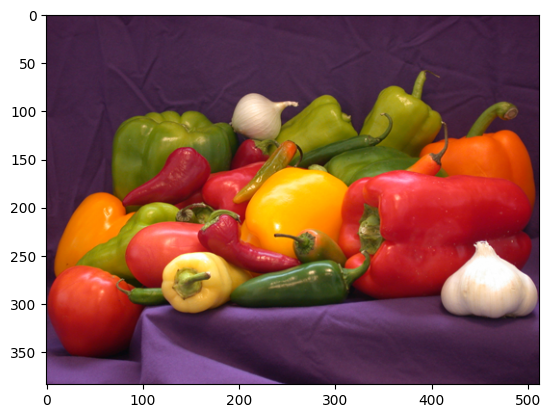

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torch
import torchvision

# Download an example image
!wget -nc -q http://www.di.ens.fr/willow/teaching/recvis_orig/assignment3/images/peppers.png
# Read the image
x = np.asarray(Image.open("peppers.png")) / 255.0
# Print the size of x. Third dimension (=3) corresponds to the R, G, B channels
print(x.shape)
# Visualize the input x
plt.imshow(x)
# Convert to torch tensor
x = torch.from_numpy(x).permute(2, 0, 1).float()
# Prepare it as a batch
x = x.unsqueeze(0)

This should display an image of bell peppers.

Next, we create a convolutional layer with a bank of 10 filters of dimension $5 \times 5 \times 3$ whose coefficients are initialized randomly. This uses the [`torch.nn.Conv2d`](https://pytorch.org/docs/stable/nn.html#torch.nn.Conv2d) module from PyTorch:

In [3]:
# Create a convolutional layer and a random bank of linear filters
conv = torch.nn.Conv2d(3, 10, kernel_size=5, stride=1, padding=0, bias=False)
print(conv.weight.size())

torch.Size([10, 3, 5, 5])


**Remark:** You might have noticed that the `bias` argument to the `torch.nn.Conv2d` function is set to `False`. When it is `True` (the default), the layer also learns a vector of bias terms, one added to the output of each filter.

Note that `conv.weight` has four dimensions, packing 10 filters. Note also that each filter is not flat, but rather a volume containing three slices. The next step is applying the filter to the image.

In [4]:
# Apply the convolution operator
y = conv(x)
# Observe the input/output sizes
print(x.size())
print(y.size())

torch.Size([1, 3, 384, 512])
torch.Size([1, 10, 380, 508])


The variable `y` contains the output of the convolution. Note that the filters are three-dimensional. This is because they operate on a tensor $\mathbf{x}$ with $K$ channels. Furthermore, there are $K'$ such filters, generating a $K'$ dimensional map $\mathbf{y}$.

We can now visualise the output `y` of the convolution. In order to do this, use the `torchvision.utils.make_grid` function to display an image for each feature channel in `y`:

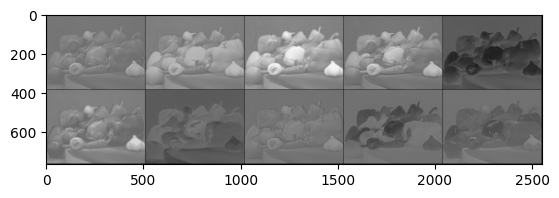

In [5]:
# Visualize the output y
def vis_features(y):
    # Organize it into 10 grayscale images
    out = y.permute(1, 0, 2, 3)
    # Scale between [0, 1]
    out = (out - out.min().expand(out.size())) / (out.max() - out.min()).expand(out.size())
    # Create a grid of images
    out = torchvision.utils.make_grid(out, nrow=5)
    # Convert to numpy image
    out = np.transpose(out.detach().numpy(), (1, 2, 0))
    # Show
    plt.imshow(out)
    # Remove grid
    plt.gca().grid(False)


vis_features(y)

So far filters preserve the resolution of the input feature map. However, it is often useful to *downsample the output*. This can be obtained by using the `stride` option in `torch.nn.Conv2d`:

torch.Size([1, 3, 384, 512])
torch.Size([1, 10, 24, 32])


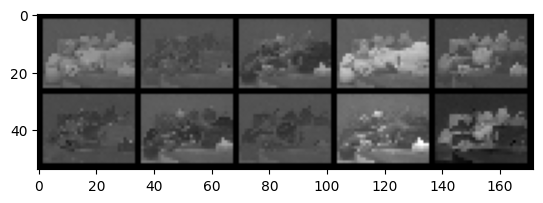

In [6]:
# Try again, downsampling the output
conv_ds = torch.nn.Conv2d(3, 10, kernel_size=5, stride=16, padding=0, bias=False)
y_ds = conv_ds(x)
print(x.size())
print(y_ds.size())
vis_features(y_ds)

Applying a filter to an image or feature map interacts with the boundaries, making the output map smaller by an amount proportional to the size of the filters. If this is undesirable, then the input array can be padded with zeros by using the `padding` option:

torch.Size([1, 3, 384, 512])
torch.Size([1, 10, 384, 512])


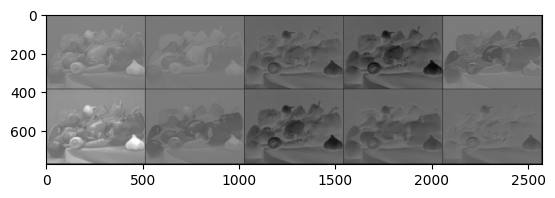

In [7]:
# Try padding
conv_pad = torch.nn.Conv2d(3, 10, kernel_size=5, stride=1, padding=2, bias=False)
y_pad = conv_pad(x)
print(x.size())
print(y_pad.size())
vis_features(y_pad)

In order to consolidate what has been learned so far, we will now design a filter by hand:


torch.Size([1, 3, 384, 512])
torch.Size([1, 1, 384, 512])


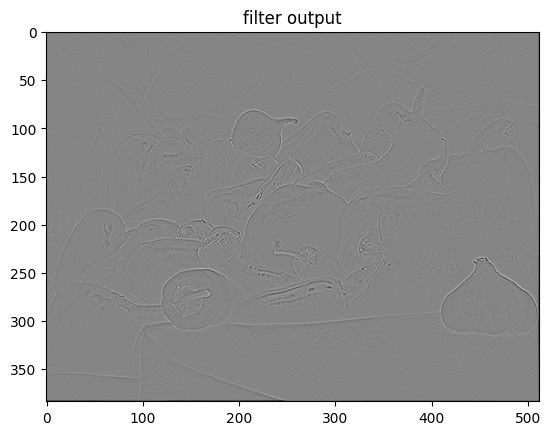

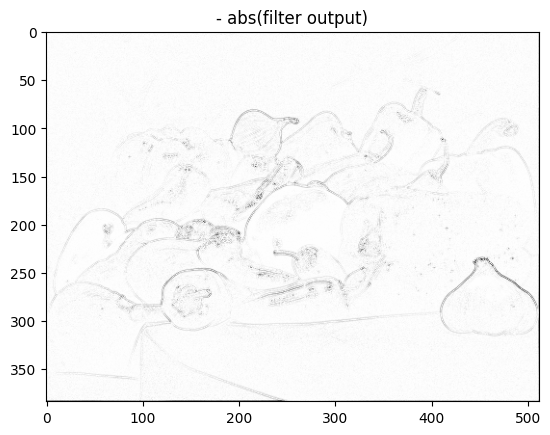

In [8]:
w = torch.FloatTensor([[0, 1, 0], [1, -4, 1], [0, 1, 0]])
w = w.repeat(3, 1).reshape(1, 3, 3, 3)
conv_lap = torch.nn.Conv2d(3, 1, kernel_size=3, stride=1, padding=1, bias=False)
conv_lap.weight = torch.nn.Parameter(w)
y_lap = conv_lap(x)
print(x.size())
print(y_lap.size())

plt.figure()
vis_features(y_lap)
plt.title("filter output")

plt.figure()
vis_features(-torch.abs(y_lap))
plt.title("- abs(filter output)");


### :: TASK 2.1 ::
* i. What filter have we implemented?
* ii. How are the RGB colour channels processed by this filter?
* iii. What image structure are detected?

<div style="border: 3px dashed #d97706; border-radius: 10px; padding: 12px; margin: 14px 0;">
<strong>✍️ REQUIRED WRITTEN RESPONSE — TASK 2.1</strong><br>
<strong>Replace the placeholder below with your response. Do not delete this heading.</strong>
</div>

#### Your response

the kernel is the following : 
$$
W =\begin{bmatrix}
    0 & 1 & 0 \\
    1 & -4 & 1 \\
    0 & 1 & 0\end{bmatrix}.
$$

To interpret this matrice, we can write this approximation of the second derivative :
$$
\frac{\partial^2 I}{\partial x^2}\approx I(x-1,y) -2I(x,y) + I(x+1,y)
$$

Therfore, we can interpret this matrice as an approximation of a derivation on the left ($I(x-1,y)-I(x,y)$), a derivation on the right ($I(x+1,y)-I(x,y)$), a derivation on the top ($I(x,y+1)-I(x,y)$)and a derivation on the bottom ($I(x,y-1)-I(x,y)$) and then everything is sum up. So this can be interpreted as the sum of the second derivative vertically (with respect to y) plus the second derivative horizontally (with respect to x). This is exactly an approximation of the laplacian operator.

Due to this code line "w = w.repeat(3, 1)", we can say that the same 3x3 kernel is duplicated to creat the weights, so the same filter is applied to each RGB channel, and then the three outputs are summed into a single one.

Based on the interpretation of the filter, it detects edges and discontinuities. Indeed, hight-frequency structures have a hight output intensity, while flat regions give a near-zero response.





## Non-linear activation functions

The simplest non-linearity is obtained by following a linear filter by a *non-linear activation function*, applied identically to each component (i.e. point-wise) of a feature map. The simplest such function is the *Rectified Linear Unit (ReLU)*
$$
  y_{ijk} = \max\{0, x_{ijk}\}.
$$
This function is implemented by [`torch.nn.ReLU()`](https://pytorch.org/docs/stable/nn.html#torch.nn.ReLU). Run the code below and understand what the filter $\mathbf{w}$ is doing.


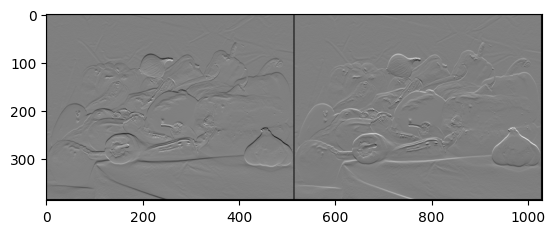

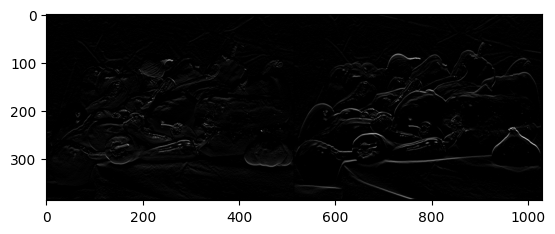

In [9]:
w = torch.FloatTensor([[1], [0], [-1]]).repeat(1, 3, 1, 1)
w = torch.cat((w, -w), 0)

conv = torch.nn.Conv2d(3, 2, kernel_size=(3, 1), stride=1, padding=0, bias=False)
conv.weight = torch.nn.Parameter(w)
relu = torch.nn.ReLU()

y = conv(x)
z = relu(y)

plt.figure()
vis_features(y)
plt.figure()
vis_features(z)

## Pooling
There are several other important operators in a CNN. One of them is *pooling*.  A pooling operator operates on individual feature channels, coalescing nearby feature values into one by the application of a suitable operator. Common choices include max-pooling (using the max operator) or sum-pooling (using summation). For example, *max-pooling* is defined as:
$$
   y_{ijk} = \max \{ y_{i'j'k} : i \leq i' < i+p, j \leq j' < j + p \}
$$
Max-pooling is implemented by [`torch.nn.MaxPool2d()`](https://pytorch.org/docs/stable/nn.html#torch.nn.MaxPool2d).

### :: TASK 2.2 ::

Run the code below to try max-pooling. Look at the resulting image. Can you interpret the result?

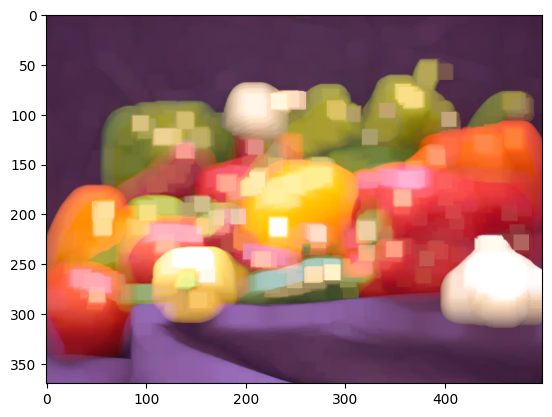

In [10]:
mp = torch.nn.MaxPool2d(15, stride=1)
y = mp(x)
plt.imshow(y.squeeze().permute(1, 2, 0).numpy())
plt.gca().grid(False)

<div style="border: 3px dashed #d97706; border-radius: 10px; padding: 12px; margin: 14px 0;">
<strong>✍️ REQUIRED WRITTEN RESPONSE — TASK 2.2</strong><br>
<strong>Replace the placeholder below with your response. Do not delete this heading.</strong>
</div>

#### Your response

For each pixel for each channel, max-pooling replaces it by the one with the highest intensity in a 15x15 window. Therefore bright structures (like light reflection on the vegetables) are expended and fine details and textures are suppressed. The image seems to have a lower resolution, however if we look at the code it is not the case because the stride is equal to one.


# Part 3 - Training a CNN

This part is an introduction to using PyTorch for training simple neural net models. CIFAR-10 dataset will be used.

## Imports

In [11]:
from __future__ import print_function
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.autograd import Variable

# Use the GPU if available (on Colab: Runtime > Change runtime type > GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


## Parameters

The default values for the learning rate, batch size and number of epochs are given in the "options" cell of this notebook. 
Unless otherwise specified, use the default values throughout this assignment. 

In [12]:
batch_size = 64  # input batch size for training
epochs = 10  # number of epochs to train
lr = 0.01  # learning rate

## Warmup





It is always good practice to visually inspect your data before trying to train a model, since it lets you check for problems and get a feel for the task at hand.

CIFAR-10 is a dataset of 60,000 color images (32 by 32 resolution) across 10 classes
(airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck). 
The train/test split is 50k/10k.

In [13]:
# Data Loading
# Warning: this cell might take some time when you run it for the first time,
#          because it will download the dataset from the internet
dataset = "cifar10"
data_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
trainset = datasets.CIFAR10(root=".", train=True, download=True, transform=data_transform)
testset = datasets.CIFAR10(root=".", train=False, download=True, transform=data_transform)

train_loader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=0)
test_loader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=0)

100%|██████████| 170M/170M [20:00<00:00, 142kB/s]  


### :: TASK 3.1 ::

Use `matplotlib` and ipython notebook's visualization capabilities to display some of these images. Display 5 images from the dataset together with their category label. [See this PyTorch tutorial page](http://pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html#sphx-glr-beginner-blitz-cifar10-tutorial-py) for hints on how to achieve this.

<div style="border: 3px solid #d97706; border-radius: 10px; padding: 12px; margin: 14px 0;">
<strong>🧩 REQUIRED CODE — TASK 3.1</strong><br>
Complete the code cell immediately below to display the necessary dataset samples.
</div>

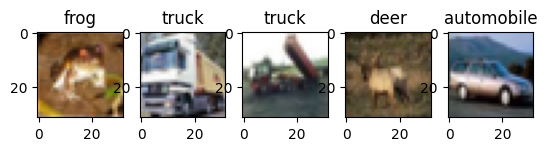

In [15]:
# ============================================================
# STUDENT TODO — TASK 3.1 (REQUIRED)
# Expected outputs: display of dataset images and labels
# Complete the indicated section and remove the
# NotImplementedError before continuing.
# ============================================================

# TODO:

classes = trainset.classes

fig, axes = plt.subplots(1,5)
for i in range(5):
    img,label = trainset[i]
    img = img/2 +0.5
    
    axes[i].imshow(img.permute(1,2,0)) #3x32x32 --> 32x32x3
    axes[i].set_title(classes[label])

plt.show()




## Training a Convolutional Network on CIFAR-10




Start by running the provided training code below. By default it will train on CIFAR-10 for 10 epochs (passes through the training data) with a single layer network. The loss function [cross_entropy](http://pytorch.org/docs/master/nn.html?highlight=cross_entropy#torch.nn.functional.cross_entropy) computes a Logarithm of the Softmax on the output of the neural network, and then computes the negative log-likelihood w.r.t. the given `target`. Note the decrease in training loss and corresponding decrease in validation errors.

In [16]:
def train(epoch, network):
    network.train()
    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = network(data)
        loss = F.cross_entropy(output, target)
        loss.backward()
        optimizer.step()
        if batch_idx % 100 == 0:
            print(
                "Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}".format(
                    epoch,
                    batch_idx * len(data),
                    len(train_loader.dataset),
                    100.0 * batch_idx / len(train_loader),
                    loss.item(),
                )
            )


@torch.no_grad()
def test(network):
    network.eval()
    test_loss = 0
    correct = 0
    for data, target in test_loader:
        data, target = data.to(device), target.to(device)
        output = network(data)
        test_loss += F.cross_entropy(output, target, reduction="sum").item()  # sum up batch loss
        pred = output.data.max(1, keepdim=True)[1]  # get the index of the max log-probability
        correct += pred.eq(target.data.view_as(pred)).cpu().sum()

    test_loss /= len(test_loader.dataset)
    print(
        "\nTest set: Average loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n".format(
            test_loss, correct, len(test_loader.dataset), 100.0 * correct / len(test_loader.dataset)
        )
    )

In [17]:
# Single layer network architecture


class Net(nn.Module):
    def __init__(self, num_inputs, num_outputs):
        super(Net, self).__init__()
        self.linear = nn.Linear(num_inputs, num_outputs)
        self.num_inputs = num_inputs

    def forward(self, input):
        input = input.view(-1, self.num_inputs)  # reshape input to batch x num_inputs
        output = self.linear(input)
        return output

In [18]:
# Train
network = Net(3072, 10).to(device)
optimizer = optim.SGD(network.parameters(), lr=lr)
for epoch in range(1, 11):
    train(epoch, network)
    test(network)

Train Epoch: 1 [0/50000 (0%)]	Loss: 2.346544
Train Epoch: 1 [6400/50000 (13%)]	Loss: 1.912039
Train Epoch: 1 [12800/50000 (26%)]	Loss: 2.044935
Train Epoch: 1 [19200/50000 (38%)]	Loss: 1.782423
Train Epoch: 1 [25600/50000 (51%)]	Loss: 1.605990
Train Epoch: 1 [32000/50000 (64%)]	Loss: 1.700738
Train Epoch: 1 [38400/50000 (77%)]	Loss: 1.667773
Train Epoch: 1 [44800/50000 (90%)]	Loss: 1.805854

Test set: Average loss: 1.8133, Accuracy: 3648/10000 (36%)

Train Epoch: 2 [0/50000 (0%)]	Loss: 1.649306
Train Epoch: 2 [6400/50000 (13%)]	Loss: 1.794287
Train Epoch: 2 [12800/50000 (26%)]	Loss: 1.806079
Train Epoch: 2 [19200/50000 (38%)]	Loss: 1.662178
Train Epoch: 2 [25600/50000 (51%)]	Loss: 1.774155
Train Epoch: 2 [32000/50000 (64%)]	Loss: 1.711142
Train Epoch: 2 [38400/50000 (77%)]	Loss: 2.002969
Train Epoch: 2 [44800/50000 (90%)]	Loss: 1.835706

Test set: Average loss: 1.7557, Accuracy: 3921/10000 (39%)

Train Epoch: 3 [0/50000 (0%)]	Loss: 1.864416
Train Epoch: 3 [6400/50000 (13%)]	Loss: 1.892

### :: TASK 3.2 ::

Add code to create a convolutional network architecture as below.

  - Convolution with 5 by 5 filters, 16 feature maps + Tanh nonlinearity.
  - 2 by 2 max pooling.
  - Convolution with 5 by 5 filters, 128 feature maps + Tanh nonlinearity.
  - 2 by 2 max pooling.
  - Flatten to vector.
  - Linear layer with 64 hidden units + Tanh nonlinearity.
  - Linear layer to 10 output units.

Use stride 1 and no padding for the convolutions. The class must be constructible as `ConvNet()` (without arguments), as in the training cell below.

<div style="border: 3px solid #d97706; border-radius: 10px; padding: 12px; margin: 14px 0;">
<strong>🧩 REQUIRED CODE — TASK 3.2</strong><br>
Complete the code cell immediately below with the CNN architecture.
</div>

In [19]:
# ============================================================
# STUDENT TODO — TASK 3.2 (REQUIRED)
# Expected outputs: a class defining the CNN architecture described above
# Complete the indicated section and remove the
# NotImplementedError before continuing.
# ============================================================


class ConvNet(nn.Module):
    # Note: it is instantiated as `ConvNet()` below, so `__init__` takes no arguments besides `self`.
    # TODO:
    def __init__(self):
        super(ConvNet, self).__init__()
        self.Conv1=torch.nn.Conv2d(in_channels=3,out_channels=16,kernel_size=5,stride=1,padding=0) #32x32x3 --> 28x28x16
        self.Maxpool = torch.nn.MaxPool2d(kernel_size=2)    #14x14x16
        self.Conv2 = torch.nn.Conv2d(in_channels=16,out_channels=128,kernel_size=5,stride=1,padding=0) #10x10x128
                                                                            #maxppol : #5x5x128
                                                                            #flatten -->3200
        self.Linear1 = torch.nn.Linear(in_features=3200,out_features=64)
        self.Linear2 = torch.nn.Linear(64,10)
        
        
        
    def forward (self,input):
        x=self.Conv1(input)
        x=torch.tanh(x)
        
        x=self.Maxpool(x)
        
        x=self.Conv2(x)
        x=torch.tanh(x)
        
        x=self.Maxpool(x)
        
        x=torch.flatten(x,start_dim=1)
        
        x=self.Linear1(x)
        x=torch.tanh(x)

        x=self.Linear2(x)
        
        return x

### :: TASK 3.3 ::

Some of the functions in a CNN must be non-linear. Why?





<div style="border: 3px dashed #d97706; border-radius: 10px; padding: 12px; margin: 14px 0;">
<strong>✍️ REQUIRED WRITTEN RESPONSE — TASK 3.3</strong><br>
<strong>Replace the placeholder below with your response. Do not delete this heading.</strong>
</div>

#### Your response

Convolutions by a filter is a linear application, so without non-linearities, a stack of convolution and linear layers boils down to a single linear function. So the depth of the network does not bring any extra expressive power. Therfore, it is not possible to learn complex features and decision frontiers on images. 

### Run the training
Train the CNN for 20 epochs on the CIFAR-10 training set.



In [20]:
# Train
network = ConvNet().to(device)
optimizer = optim.SGD(network.parameters(), lr=lr)
for epoch in range(1, 21):
    train(epoch, network)
    test(network)

Train Epoch: 1 [0/50000 (0%)]	Loss: 2.311463
Train Epoch: 1 [6400/50000 (13%)]	Loss: 2.178946
Train Epoch: 1 [12800/50000 (26%)]	Loss: 2.113123
Train Epoch: 1 [19200/50000 (38%)]	Loss: 1.848451
Train Epoch: 1 [25600/50000 (51%)]	Loss: 1.875668
Train Epoch: 1 [32000/50000 (64%)]	Loss: 1.922267
Train Epoch: 1 [38400/50000 (77%)]	Loss: 1.757697
Train Epoch: 1 [44800/50000 (90%)]	Loss: 1.810453

Test set: Average loss: 1.7801, Accuracy: 3814/10000 (38%)

Train Epoch: 2 [0/50000 (0%)]	Loss: 1.764765
Train Epoch: 2 [6400/50000 (13%)]	Loss: 1.788086
Train Epoch: 2 [12800/50000 (26%)]	Loss: 1.750579
Train Epoch: 2 [19200/50000 (38%)]	Loss: 1.723130
Train Epoch: 2 [25600/50000 (51%)]	Loss: 1.748055
Train Epoch: 2 [32000/50000 (64%)]	Loss: 1.559685
Train Epoch: 2 [38400/50000 (77%)]	Loss: 1.727615
Train Epoch: 2 [44800/50000 (90%)]	Loss: 1.540136

Test set: Average loss: 1.6122, Accuracy: 4285/10000 (43%)

Train Epoch: 3 [0/50000 (0%)]	Loss: 1.710286
Train Epoch: 3 [6400/50000 (13%)]	Loss: 1.686

### :: TASK 3.4 ::
Plot the first convolutional layer weights as images after the last epoch. (Hint threads: [#1](https://discuss.pytorch.org/t/understanding-deep-network-visualize-weights/2060/2?u=smth) [#2](https://github.com/pytorch/vision#utils) )

<div style="border: 3px solid #d97706; border-radius: 10px; padding: 12px; margin: 14px 0;">
<strong>🧩 REQUIRED CODE — TASK 3.4</strong><br>
Complete the code cell immediately below with the visualization of the first convolutional layer weights.
</div>

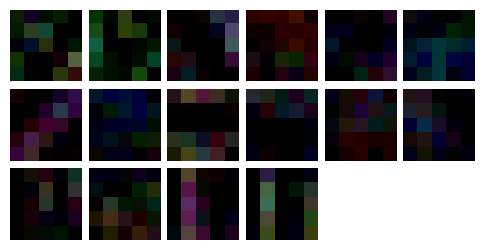

In [ ]:
# ============================================================
# STUDENT TODO — TASK 3.4 (REQUIRED)
# Expected outputs: 16 RGB images, one per 3x5x5 filter
# Complete the indicated section and remove the
# NotImplementedError before continuing.
# ============================================================

# TODO:

#This function is the code of "Fchaubard" in the thread #1
def plot_kernels(tensor, num_cols=6):
    if not tensor.ndim==4:
        raise Exception("assumes a 4D tensor")
    if not tensor.shape[-1]==3:
        raise Exception("last dim needs to be 3 to plot")
    num_kernels = tensor.shape[0]
    num_rows = 1+ num_kernels // num_cols
    fig = plt.figure(figsize=(num_cols,num_rows))
    for i in range(tensor.shape[0]):
        ax1 = fig.add_subplot(num_rows,num_cols,i+1)
        ax1.imshow(tensor[i])
        ax1.axis('off')
        ax1.set_xticklabels([])
        ax1.set_yticklabels([])

    plt.subplots_adjust(wspace=0.1, hspace=0.1)
    plt.show()
 
#adaptation of the input of the function for a convolutional network in our form (in the original it is a nn.Sequential I think)
tensor = network.Conv1.weight.detach().cpu().numpy()
tensor = tensor.transpose(0, 2, 3, 1) #batch x H x W x C
plot_kernels(tensor)

### :: TASK 3.5 :: 

What is the size (channels × height × width) of the feature map after each layer, starting from the $3\times32\times32$ input? What is the dimensionality of the weights at each layer? How many parameters are there in total in this CNN architecture?

<div style="border: 3px dashed #d97706; border-radius: 10px; padding: 12px; margin: 14px 0;">
<strong>✍️ REQUIRED WRITTEN RESPONSE — TASK 3.5</strong><br>
<strong>Replace the placeholder below with your response. Do not delete this heading.</strong>
</div>

#### Your response

| Layer | size of the feature map ( of the form Channels x Height xWidth) | Weights shape | Bias (we kept them in ConvNet) | number of parameters |
|-------|----------------------|-----------|------------|---------------|
| Input | 3×32×32 | None | None | 0 |
| Conv1 | 16×28×28 | 16×3×5×5 | 16 | 16×3×5×5 +16 = 1216 |
| Tanh | 16×28×28 | None | None| 0 |
| MaxPool | 16×14×14 | None| None| 0 |
| Conv2 | 128×10×10 | 128×16×5×5 | 128 | 128×16×5×5+128 =51328 |
| Tanh | 128×10×10 | None| None | 0 |
| MaxPool | 128×5×5 | None| None | 0 |
| Flatten | 3200 | None | None| 0 |
| Linear1 | 64 | 64×3200 | 64 | 64×3200 +64 =204864 |
| Tanh | 64 | None | None | 0 |
| Linear2 | 10 | 10×64 | 10 | 10×64 +10 = 650 |
| Total | | | | 258058 |


To justify the size of the feature maps, we have to taker into account the padding=0 and the stride=1: the spatial size becomes $H' = H - k + 1$ (same for W).\
For a 2x2 max-pooling with stride 2, the spatial size is divided by 2. \
The number of channels is given by the output_size value. \
Flatten just reshapes 128x5x5 into a vector of size 3200.\
The linear layers change this size into 64 and then 10.



To justify the number of parameters in a layer, one can interpret it as a matrix multiplication, where the weights correspond to the elements of the matrix. For a linear layer, each element of the matrice is a scalar, so the number of parameters is just the size of the matrice. For convolutionnal layers, the elements of the matrice are kernels of size kernel_size x kernel_size. So the number of parameters is the number of elements in the matrice times the kernel shape. Then we just add the biais.



## Useful resources

  - [PyTorch tutorial](http://pytorch.org/tutorials/beginner/blitz/neural_networks_tutorial.html#sphx-glr-beginner-blitz-neural-networks-tutorial-py)
  - [MNIST example](https://github.com/pytorch/examples/tree/master/mnist)

## AUTHORSHIP STATEMENT

I declare that the preceding work was the sole result of my own effort and that I have not used any code or results from third-parties.

Aimine MEDDEB